## Loading Data:
I decided to add year when loading each data file so it's easier to split the data chronologically and for the audit. I will not be using CO as it's an output of the gas turbine rather than a feature that can be used to help predict NOx values. Year and CO won't be used as features as seen by my Features list which exclude both.

In [1]:
import sys, platform
print(platform.python_version())
print(sys.executable)   # this should point inside your .venv

FEATURES = ["AT","AP","AH","AFDP","GTEP","TIT","TAT","TEY","CDP"]
TARGET = "NOX"

3.14.7
C:\Users\omars\Documents\GitHub\CT4101-ML\.venv\Scripts\python.exe


In [3]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("..") / "data"

frames = []
for y in range(2011, 2016):
    d = pd.read_csv(DATA_DIR / f"gt_{y}.csv")
    d["year"] = y
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
print(df.shape)
print(df.groupby("year").size())

(36733, 12)
year
2011    7411
2012    7628
2013    7152
2014    7158
2015    7384
dtype: int64


## Data Audit:


In [5]:
# Shape, types & missing
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

(36733, 12)
AT      float64
AP      float64
AH      float64
AFDP    float64
GTEP    float64
TIT     float64
TAT     float64
TEY     float64
CDP     float64
CO      float64
NOX     float64
year      int64
dtype: object
AT      0
AP      0
AH      0
AFDP    0
GTEP    0
TIT     0
TAT     0
TEY     0
CDP     0
CO      0
NOX     0
year    0
dtype: int64


Shape is 36,733 rows and 12 columns, 1 being the year we added. The rest are the features e.g. "AT","AP"& "AH" and then CO and NOx. All sensor values are continous float64, so we don't need encoding and only year is int64. There are no missing values so we don't need to remove any rows or do imputation. However not every hour in every year is recorded, we don't know how big the gaps between each hour is only that is chronological.

In [6]:
# Duplicates
print(df.duplicated().sum())
print(df[df.duplicated(keep=False)].groupby("year").size())

7
year
2014    9
dtype: int64


7 duplicates total in the dataset, it says 9 in 2014 as it includes the originals and the repeats, so 2 original rows and 7 repeats. I will keep these values for 2 reasons. 1. As the repeats are in the test set and won't affect the training. 2. The 2014 data has 7158 rows and 2015 data has 7384 rows, so 14542 test rows total, 7/14542 = 0.00048, 0.00048% of the test set has repeated data which is negligible.

min: 25.905
max: 119.91
mean: 65.29306726921297
median: 63.849
skew: 1.0267788505165132
rows below 40: 24
year
2011    67.575392
2012    68.788965
2013    70.007899
2014    60.066886
2015    59.890509
Name: NOX, dtype: float64


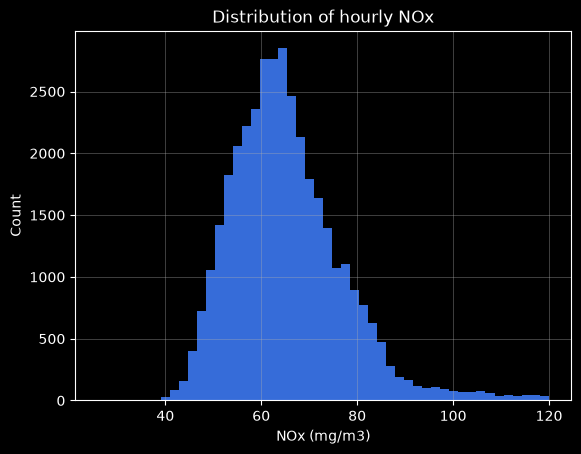

In [11]:
# Target distribution
import matplotlib.pyplot as plt

target = df[TARGET]

print("min:", target.min())
print("max:", target.max())
print("mean:", target.mean())
print("median:", target.median())
print("skew:", target.skew())
print("rows below 40:", (target < 40).sum())
print(target.groupby(df["year"]).mean())

target.hist(bins=50)
plt.xlabel("NOx (mg/m3)"); plt.ylabel("Count"); plt.title("Distribution of hourly NOx"); plt.show()

NOx peak is around 60-65 mg/m3, it has a long right tail that reaches as far as 120 mg/m3, its range is from 25.905-119.91, it has a mean of 65.29 and has a median of 63.85. Looking at the histogram and the skew value we can see that there is a moderate right skew. Since it's only a moderate skew where the tail only affects a small amount of rows and I plan on using random forest and gradient boosting which don't need a symmetric distribution, I won't be transforming NOx into Log Nox. However, it may be useful for a linear model and may do so on the validation folds but not on the test set. The skew is another reason why I will be using MAE as my main metric instead of RMSE since it's less affected by a few large values. The mean will also be pulled right due to this skew. Lastly, there is a drift in mean NOx values for each year, 2011-2013 has a range of 67.58-70.01 but 2014-2015 is about 60, with 2014 having a mean of 60.07 & 2015 a mean of 59.89, the mean NOx for the last 2 years is lower than the first 3 years. Due to this drift I expect a worse performance on the test years than in the cross validation.

max: 550.61
share of rows >= 549: 0.674243867911687


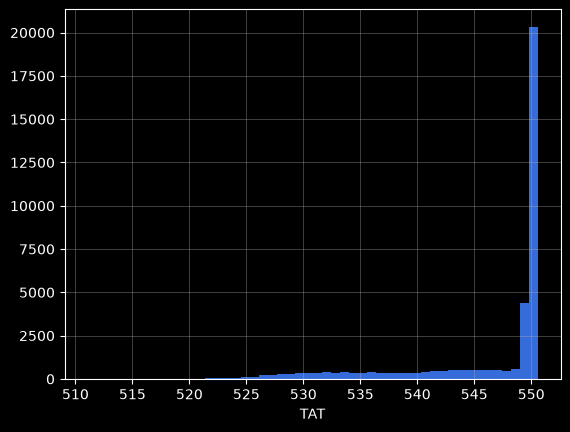

AT         1
AP       612
AH       132
AFDP     557
GTEP       7
TIT      315
TAT     4955
TEY       33
CDP       10
CO      2655
NOX      936
dtype: int64

In [16]:
# Outliers (1.5 x IQR rule)

tat = df["TAT"]
print("max:", tat.max())
print("share of rows >= 549:", (tat >= 549).mean())
tat.hist(bins=50); plt.xlabel("TAT"); plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    return ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum()

df.drop(columns="year").apply(iqr_outliers)

I've used the 1.5 X IQR rule as it doesn't require a normal distribution. Most columns have few flagged values e.g. CDP 10, TEY 33 & AH 132. There are large counts e.g. TAT 4955, CO 2655 & NOx 936, however for NOx 936/36733 = 2.55% which is a small amount of the total number of NOx values in the dataset. TAT's count can be explained by looking at its histogram, it has a cap of around 550 and most of its values sit against this cap, 67% of TAT values are 549 or above, this makes the IQR small and the rule only flags the values distributed on the left tail. Due to this, TAT may be less informative compared to other features. I will not remove these values as they don't seem to be errors with the sensors but real world conditions and I have no proof that they are wrong. In addition, MAE and the tree based models are less sensitive to them. However, linear regression may be sensitive to them.  CO is an output value that I'm not predicting and not a feature so it's count doesn't matter to the models.